In [32]:
import warnings #

import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.model_selection import train_test_split, RandomizedSearchCV

from sklearn.preprocessing import StandardScaler

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor


from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("gym_crowdedness.csv")

In [3]:
df.head()

,number_people,date,timestamp,day_of_week,is_weekend,is_holiday,temperature,is_start_of_semester,is_during_semester,month,hour
0,37,2015-08-14 17:00:11-07:00,61211,4,0,0,71.76,0,0,8,17
1,45,2015-08-14 17:20:14-07:00,62414,4,0,0,71.76,0,0,8,17
2,40,2015-08-14 17:30:15-07:00,63015,4,0,0,71.76,0,0,8,17
3,44,2015-08-14 17:40:16-07:00,63616,4,0,0,71.76,0,0,8,17
4,45,2015-08-14 17:50:17-07:00,64217,4,0,0,71.76,0,0,8,17


In [4]:
df.columns

Index(['number_people', 'date', 'timestamp', 'day_of_week', 'is_weekend',
       'is_holiday', 'temperature', 'is_start_of_semester',
       'is_during_semester', 'month', 'hour'],
      dtype='object')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62184 entries, 0 to 62183
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   number_people         62184 non-null  int64  
 1   date                  62184 non-null  object 
 2   timestamp             62184 non-null  int64  
 3   day_of_week           62184 non-null  int64  
 4   is_weekend            62184 non-null  int64  
 5   is_holiday            62184 non-null  int64  
 6   temperature           62184 non-null  float64
 7   is_start_of_semester  62184 non-null  int64  
 8   is_during_semester    62184 non-null  int64  
 9   month                 62184 non-null  int64  
 10  hour                  62184 non-null  int64  
dtypes: float64(1), int64(9), object(1)
memory usage: 5.2+ MB


In [6]:
df.describe()

,number_people,timestamp,day_of_week,is_weekend,is_holiday,temperature,is_start_of_semester,is_during_semester,month,hour
count,62184.000000,62184.000000,62184.000000,62184.000000,62184.000000,62184.000000,62184.000000,62184.000000,62184.000000,62184.000000
mean,29.072543,45799.437958,2.982504,0.282870,0.002573,58.557108,0.078831,0.660218,7.439824,12.236460
std,22.689026,24211.275891,1.996825,0.450398,0.050660,6.316396,0.269476,0.473639,3.445069,6.717631
min,0.000000,0.000000,0.000000,0.000000,0.000000,38.140000,0.000000,0.000000,1.000000,0.000000
25%,9.000000,26624.000000,1.000000,0.000000,0.000000,55.000000,0.000000,0.000000,5.000000,7.000000
50%,28.000000,46522.500000,3.000000,0.000000,0.000000,58.340000,0.000000,1.000000,8.000000,12.000000
75%,43.000000,66612.000000,5.000000,1.000000,0.000000,62.280000,0.000000,1.000000,10.000000,18.000000
max,145.000000,86399.000000,6.000000,1.000000,1.000000,87.170000,1.000000,1.000000,12.000000,23.000000


In [7]:
df["date"] = pd.to_datetime(df["date"], utc=True)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62184 entries, 0 to 62183
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype              
---  ------                --------------  -----              
 0   number_people         62184 non-null  int64              
 1   date                  62184 non-null  datetime64[ns, UTC]
 2   timestamp             62184 non-null  int64              
 3   day_of_week           62184 non-null  int64              
 4   is_weekend            62184 non-null  int64              
 5   is_holiday            62184 non-null  int64              
 6   temperature           62184 non-null  float64            
 7   is_start_of_semester  62184 non-null  int64              
 8   is_during_semester    62184 non-null  int64              
 9   month                 62184 non-null  int64              
 10  hour                  62184 non-null  int64              
dtypes: datetime64[ns, UTC](1), float64(1), int64(9)
memory usage: 5.2 M

In [9]:
df["year"] = df["date"].dt.year

In [10]:
df.drop("date", axis=1, inplace=True)

In [11]:
df.head()

,number_people,timestamp,day_of_week,is_weekend,is_holiday,temperature,is_start_of_semester,is_during_semester,month,hour,year
0,37,61211,4,0,0,71.76,0,0,8,17,2015
1,45,62414,4,0,0,71.76,0,0,8,17,2015
2,40,63015,4,0,0,71.76,0,0,8,17,2015
3,44,63616,4,0,0,71.76,0,0,8,17,2015
4,45,64217,4,0,0,71.76,0,0,8,17,2015


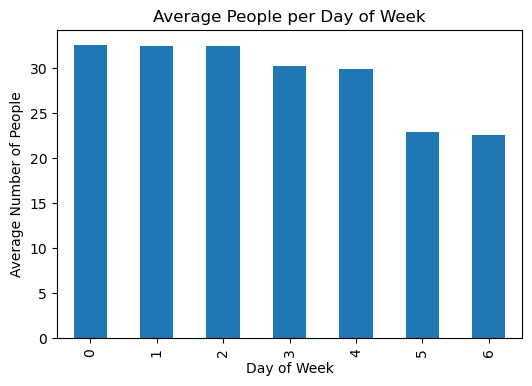

In [12]:
day_avg = df.groupby('day_of_week')['number_people'].mean()

plt.figure(figsize=(6,4))
day_avg.plot(kind='bar')
plt.xlabel('Day of Week')
plt.ylabel('Average Number of People')
plt.title('Average People per Day of Week')
plt.show()

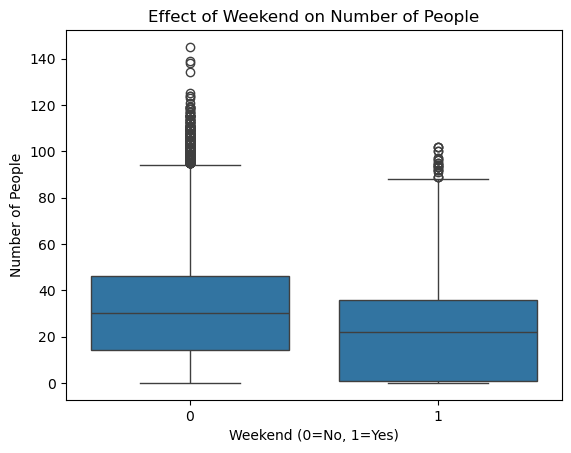

In [13]:
sns.boxplot(x='is_weekend', y='number_people', data=df)
plt.xlabel('Weekend (0=No, 1=Yes)')
plt.ylabel('Number of People')
plt.title('Effect of Weekend on Number of People')
plt.show()

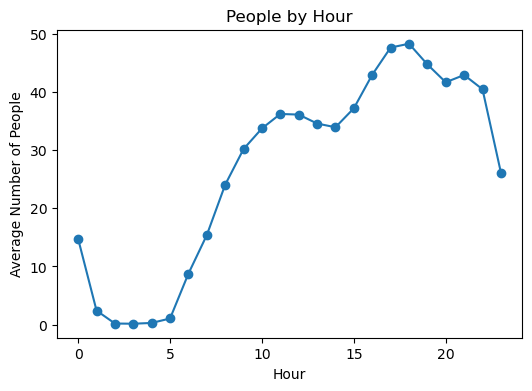

In [14]:
hour_avg = df.groupby('hour')['number_people'].mean()

plt.figure(figsize=(6,4))
hour_avg.plot(kind='line', marker='o')
plt.xlabel('Hour')
plt.ylabel('Average Number of People')
plt.title('People by Hour')
plt.show()

In [15]:
df.drop("timestamp", axis=1, inplace=True)

In [16]:
X = df.drop("number_people", axis=1)
y = df["number_people"]

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.25, random_state=15)

In [17]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [18]:
def calculate_model_metrics(true, predicted):
    mse = mean_squared_error(true, predicted)
    mae = mean_absolute_error(true, predicted)
    rmse = np.sqrt(mean_squared_error(true, predicted))
    r2_square = r2_score(true, predicted)
    return mse, mae, rmse, r2_square

In [19]:
models = {
    "Linear Regression" : LinearRegression(),
    "Ridge" : Ridge(),
    "Lasso" : Lasso(),
    "K-Neighbors Regressor" : KNeighborsRegressor(),
    "DecisionTree Regressor" : DecisionTreeRegressor(),
    "RandomForest Regressor" : RandomForestRegressor()
}

In [20]:
for i in range(len(list(models))):
    model = list(models.values())[i]
    model.fit(X_train, y_train)

    y_train_pred = model.predict(X_train) #buna bakma nedenimimiz train accuracy yuksek ve test accuracy dusukse overfitting var diyebiliriz.
    y_test_pred = model.predict(X_test)

    model_train_mse, model_train_mae, model_train_rmse, model_train_r2_square = calculate_model_metrics(y_train, y_train_pred)
    model_test_mse, model_test_mae, model_test_rmse, model_test_r2_square = calculate_model_metrics(y_test, y_test_pred)

    print(model)
    print("Evaulation for Training Set")
    print("RMSE: ", model_train_rmse)
    print("MAE: ", model_train_mae)
    print("MSE: ", model_train_mse)
    print("R2 Square Score: ", model_train_r2_square)

    print("\n")
    
    print("Evaulation for Test Set")
    print("RMSE: ", model_test_rmse)
    print("MAE: ", model_test_mae)
    print("MSE: ", model_test_mse)
    print("R2 Square Score: ", model_test_r2_square)

    print("-"*40)
    print("\n")

LinearRegression()
Evaulation for Training Set
RMSE:  14.322500408269727
MAE:  10.733469936454322
MSE:  205.1340179448865
R2 Square Score:  0.5999639521710998


Evaulation for Test Set
RMSE:  14.45063290337055
MAE:  10.779752371029556
MSE:  208.8207913079756
R2 Square Score:  0.5989271376662775
----------------------------------------


Ridge()
Evaulation for Training Set
RMSE:  14.322500413912243
MAE:  10.7334791788207
MSE:  205.13401810651635
R2 Square Score:  0.5999639518559021


Evaulation for Test Set
RMSE:  14.450633329986024
MAE:  10.77975955902301
MSE:  208.82080363770297
R2 Square Score:  0.5989271139851151
----------------------------------------


Lasso()
Evaulation for Training Set
RMSE:  14.569122351126817
MAE:  10.94518987422199
MSE:  212.259326082103
R2 Square Score:  0.5860687429058037


Evaulation for Test Set
RMSE:  14.703511215751082
MAE:  10.970594902476911
MSE:  216.19324207171786
R2 Square Score:  0.5847671974050243
----------------------------------------


KNeig

In [21]:
#hyperParameter Tuning

In [22]:
knn_params = {"n_neighbors" : [2,3,10,20,40,50]}
rf_params = {
    "n_estimators" : [100,200,500,1000],
    "max_depth" : [5,8,10,15,None],
    "max_features" : ["sqrt", "log2", ],
    "min_samples_split" : [2,8,12,20]
}

In [23]:
randomcv_models = [
    ("KNN", KNeighborsRegressor(), knn_params),
    ("RF", RandomForestRegressor(), rf_params)
]

In [35]:
for name, model, params in randomcv_models:
    randomcv = RandomizedSearchCV(
        estimator=model,
        param_distributions=params,
        n_iter=100,
        cv=3,
        n_jobs=-1
    )

    randomcv.fit(X_train, y_train)
    print("Best Parameters for: ", name, randomcv.best_params_)

Best Parameters for:  KNN {'n_neighbors': 2}


Exception ignored in: <function ResourceTracker.__del__ at 0x79e33458a2a0>
Traceback (most recent call last):
  File "/home/yusuf/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/home/yusuf/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/home/yusuf/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x79d96a78a2a0>
Traceback (most recent call last):
  File "/home/yusuf/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/home/yusuf/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/home/yusuf/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ 

Best Parameters for:  RF {'n_estimators': 1000, 'min_samples_split': 2, 'max_features': 'sqrt', 'max_depth': None}


In [90]:
models_1 = {
    "K-Neighbors Regressor" : KNeighborsRegressor(n_neighbors=2),
    "RandomForest Regressor" : RandomForestRegressor(n_estimators=1000, min_samples_split=2, max_features="log2", max_depth=None)
}

In [91]:
for i in range(len(list(models_1))):
    model = list(models_1.values())[i]
    model.fit(X_train, y_train)

    y_train_pred = model.predict(X_train) #buna bakma nedenimimiz train accuracy yuksek ve test accuracy dusukse overfitting var diyebiliriz.
    y_test_pred = model.predict(X_test)

    model_train_mse, model_train_mae, model_train_rmse, model_train_r2_square = calculate_model_metrics(y_train, y_train_pred)
    model_test_mse, model_test_mae, model_test_rmse, model_test_r2_square = calculate_model_metrics(y_test, y_test_pred)

    print(model)
    print("Evaulation for Training Set")
    print("RMSE: ", model_train_rmse)
    print("MAE: ", model_train_mae)
    print("MSE: ", model_train_mse)
    print("R2 Square Score: ", model_train_r2_square)

    print("\n")
    
    print("Evaulation for Test Set")
    print("RMSE: ", model_test_rmse)
    print("MAE: ", model_test_mae)
    print("MSE: ", model_test_mse)
    print("R2 Square Score: ", model_test_r2_square)

    print("-"*40)
    print("\n")

KNeighborsRegressor(n_neighbors=2)
Evaulation for Training Set
RMSE:  5.454986474685179
MAE:  3.5539152622325143
MSE:  29.75687743899824
R2 Square Score:  0.9419705041334293


Evaulation for Test Set
RMSE:  6.906627163661049
MAE:  4.635983532741541
MSE:  47.70149877782066
R2 Square Score:  0.9083818400811778
----------------------------------------


RandomForestRegressor(max_features='log2', n_estimators=1000)
Evaulation for Training Set
RMSE:  4.708960913373836
MAE:  3.197475711997062
MSE:  22.174312883682553
R2 Square Score:  0.9567574185004601


Evaulation for Test Set
RMSE:  6.4186708400553565
MAE:  4.294167566052095
MSE:  41.19933535297694
R2 Square Score:  0.9208702579241961
----------------------------------------


